In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy
import random
from utils import wasserstein

seed = 1234
batch_size = 1144
dim = 2
random.seed(seed)
np.random.seed(seed)

with open(r".\data\stateFate_inVitro_metadata\stateFate_inVitro_metadata.txt", 'r') as f:
    lines = f.readlines()
datas = []
for l in lines:
    data = []
    for d in l.strip().split('\t'):
        if d:
            data.append(d)
    datas.append(data)
for d in datas[:10]:
    print(d)

['Library', 'Cell_barcode', 'Time_point', 'Starting_population', 'Cell_type_annotation', 'Well', 'SPRING-x', 'SPRING-y']
['d6_2_2', 'GCGTGCAA-AGAAGTTA', '6.0', 'Lin-Kit+Sca1-', 'Undifferentiated', '2', '411.496', '-96.19']
['d6_2_2', 'AAGGGACC-CTCGATGC', '6.0', 'Lin-Kit+Sca1-', 'Undifferentiated', '2', '-587.462', '-306.925']
['d6_2_2', 'CGTACCGA-AGCGCCTT', '6.0', 'Lin-Kit+Sca1-', 'Monocyte', '2', '1429.805', '-429.3']
['d6_2_2', 'CTGAAGGG-AGGAGCTT', '6.0', 'Lin-Kit+Sca1-', 'Neutrophil', '2', '1150.028', '-2030.369']
['d6_2_2', 'CCGTAGCT-AGGCAGTT', '6.0', 'Lin-Kit+Sca1-', 'Undifferentiated', '2', '-1169.594', '362.01']
['d6_2_2', 'GGCTTTGC-CGAACGTA', '6.0', 'Lin-Kit+Sca1-', 'Neutrophil', '2', '1387.371', '-2197.327']
['d6_2_2', 'TAGGCTTT-CGTGGATA', '6.0', 'Lin-Kit+Sca1-', 'Neutrophil', '2', '1236.039', '-2113.013']
['d6_2_2', 'GGCCCAAT-GTTTACGT', '6.0', 'Lin-Kit+Sca1-', 'Undifferentiated', '2', '972.471', '482.738']
['d6_2_2', 'AAGTCGGG-GGCCTAAG', '6.0', 'Lin-Kit+Sca1-', 'Monocyte', '2

In [32]:
member = []
with open(r"D:\bio\MSB\data\stateFate_inVitro_clone_matrix.mtx", 'r') as f:
    flg = 0
    for l in f:
        if l.startswith('%'):
            print(l)
            continue
        else:
            if not flg:
                flg = 1
                print(l)
                continue
            else:
                ll = l.strip().split(' ')
                member.append((int(ll[0]), int(ll[1])))
member 



%%MatrixMarket matrix coordinate integer general

% Generated from file without header

130887 5864 49302



[(83394, 1),
 (84421, 1),
 (124799, 1),
 (124872, 1),
 (128165, 1),
 (32617, 2),
 (32673, 2),
 (35644, 2),
 (35845, 2),
 (37084, 2),
 (63604, 2),
 (64444, 2),
 (64512, 2),
 (65681, 2),
 (66294, 2),
 (66333, 2),
 (66363, 2),
 (66421, 2),
 (66434, 2),
 (66606, 2),
 (68098, 2),
 (68231, 2),
 (68249, 2),
 (112639, 2),
 (116446, 2),
 (39168, 3),
 (39908, 3),
 (41048, 3),
 (64875, 3),
 (66052, 3),
 (66088, 3),
 (66157, 3),
 (66335, 3),
 (66402, 3),
 (66441, 3),
 (66586, 3),
 (66998, 3),
 (67544, 3),
 (67813, 3),
 (67920, 3),
 (68133, 3),
 (68403, 3),
 (69153, 3),
 (112936, 3),
 (119243, 3),
 (84898, 4),
 (88020, 4),
 (62463, 5),
 (63712, 5),
 (64804, 5),
 (113429, 5),
 (113474, 5),
 (115782, 5),
 (117527, 5),
 (117704, 5),
 (120058, 5),
 (47401, 6),
 (70156, 6),
 (71104, 6),
 (75225, 6),
 (80683, 6),
 (81704, 6),
 (48981, 7),
 (128788, 7),
 (631, 8),
 (24693, 8),
 (909, 9),
 (1439, 9),
 (8038, 9),
 (10551, 9),
 (21969, 9),
 (25722, 9),
 (93099, 10),
 (124056, 10),
 (42055, 11),
 (82337, 11),

In [33]:
with open(r"D:\bio\MSB\data\stateFate_inVitro_neutrophil_monocyte_trajectory.txt", 'r') as f:
    lines = f.readlines()
idx = []
for l in lines:
    idx.append(l.strip())
idx = list(map(int, idx[1:]))
idx

[0,
 2,
 3,
 5,
 6,
 7,
 8,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 19,
 21,
 22,
 23,
 24,
 25,
 26,
 28,
 29,
 30,
 31,
 32,
 33,
 34,
 36,
 37,
 38,
 39,
 40,
 41,
 43,
 44,
 45,
 46,
 47,
 48,
 49,
 50,
 51,
 53,
 54,
 56,
 58,
 59,
 60,
 61,
 62,
 63,
 64,
 65,
 66,
 67,
 68,
 69,
 70,
 71,
 72,
 73,
 74,
 75,
 76,
 77,
 78,
 79,
 80,
 81,
 82,
 88,
 90,
 92,
 93,
 94,
 95,
 96,
 98,
 99,
 100,
 101,
 103,
 104,
 106,
 107,
 108,
 109,
 110,
 111,
 113,
 114,
 115,
 117,
 118,
 119,
 122,
 123,
 128,
 130,
 131,
 132,
 133,
 134,
 136,
 138,
 140,
 142,
 143,
 144,
 145,
 146,
 148,
 149,
 152,
 153,
 155,
 156,
 160,
 161,
 162,
 163,
 164,
 166,
 167,
 169,
 171,
 172,
 173,
 174,
 175,
 176,
 178,
 179,
 180,
 181,
 182,
 183,
 184,
 185,
 186,
 187,
 188,
 189,
 191,
 193,
 194,
 196,
 198,
 199,
 200,
 201,
 202,
 203,
 207,
 209,
 213,
 214,
 215,
 216,
 217,
 219,
 221,
 222,
 223,
 224,
 225,
 226,
 227,
 228,
 229,
 231,
 232,
 238,
 239,
 240,
 241,
 242,
 243,
 244,
 2

In [34]:

df = pd.DataFrame(datas[1:], columns=datas[0])
print(df)
df['Time_point'] = pd.to_numeric(df['Time_point'])
df['SPRING-x'] = pd.to_numeric(df['SPRING-x'])
df['SPRING-y'] = pd.to_numeric(df['SPRING-y'])
df['SPRING-x'].dtype
df['Member'] = 0
print(min(member, key=lambda x: x[0]))
print(max(member, key=lambda x: x[0]))

for m in member:
    df.loc[m[0]-1, 'Member'] = m[1]
df = df.iloc[idx]
df = df[df['Member'] != 0]
df


           Library       Cell_barcode Time_point Starting_population  \
0           d6_2_2  GCGTGCAA-AGAAGTTA        6.0       Lin-Kit+Sca1-   
1           d6_2_2  AAGGGACC-CTCGATGC        6.0       Lin-Kit+Sca1-   
2           d6_2_2  CGTACCGA-AGCGCCTT        6.0       Lin-Kit+Sca1-   
3           d6_2_2  CTGAAGGG-AGGAGCTT        6.0       Lin-Kit+Sca1-   
4           d6_2_2  CCGTAGCT-AGGCAGTT        6.0       Lin-Kit+Sca1-   
...            ...                ...        ...                 ...   
130882  LSK_d6_1_3  TCTGATTT-CGGGCTTT        6.0       Lin-Kit+Sca1+   
130883  LSK_d6_1_3  AGTCACAA-TGTGTCCT        6.0       Lin-Kit+Sca1+   
130884  LSK_d6_1_3  GGAGGTTT-AGGCAGTT        6.0       Lin-Kit+Sca1+   
130885  LSK_d6_1_3  CCGGAAAT-GGGAAGGT        6.0       Lin-Kit+Sca1+   
130886  LSK_d6_1_3  GTATTGAC-GGGTGTAT        6.0       Lin-Kit+Sca1+   

       Cell_type_annotation Well   SPRING-x   SPRING-y  
0          Undifferentiated    2    411.496     -96.19  
1          Undifferen

,Library,Cell_barcode,Time_point,Starting_population,Cell_type_annotation,Well,SPRING-x,SPRING-y,Member
0,d6_2_2,GCGTGCAA-AGAAGTTA,6.0,Lin-Kit+Sca1-,Undifferentiated,2,411.496,-96.190,574
2,d6_2_2,CGTACCGA-AGCGCCTT,6.0,Lin-Kit+Sca1-,Monocyte,2,1429.805,-429.300,395
6,d6_2_2,TAGGCTTT-CGTGGATA,6.0,Lin-Kit+Sca1-,Neutrophil,2,1236.039,-2113.013,1451
8,d6_2_2,AAGTCGGG-GGCCTAAG,6.0,Lin-Kit+Sca1-,Monocyte,2,2617.548,-248.370,5625
13,d6_2_2,ATCCTAGT-AATCGGGT,6.0,Lin-Kit+Sca1-,Neutrophil,2,534.770,-1041.463,1653
...,...,...,...,...,...,...,...,...,...
130874,LSK_d6_1_3,CTGTGACC-TGCTATTT,6.0,Lin-Kit+Sca1+,Undifferentiated,1,307.879,-27.451,5000
130876,LSK_d6_1_3,CGTGCAAC-TGGCCTGT,6.0,Lin-Kit+Sca1+,Undifferentiated,1,247.634,281.262,268
130877,LSK_d6_1_3,CCCTTGCA-AGTGAAAG,6.0,Lin-Kit+Sca1+,Neutrophil,1,353.734,-980.246,3535
130879,LSK_d6_1_3,TCCGCTGT-GACAGATA,6.0,Lin-Kit+Sca1+,Monocyte,1,2513.013,-324.061,4946


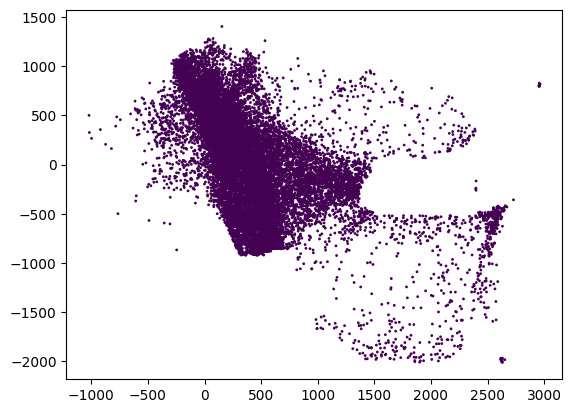

In [35]:
cs = []; cdic={}
i = 0
mask = df['Cell_type_annotation'] == 'Undifferentiated'

for typ in df[mask]['Cell_type_annotation']:
    if typ not in cdic:
        cdic[typ] = i
        i+=1
    cs.append(cdic[typ])
plt.scatter(df[mask]['SPRING-x'], df[mask]['SPRING-y'], s=1, c=cs)

In [36]:
Mo = df[df['Cell_type_annotation'] == 'Monocyte'][['SPRING-x', 'SPRING-y']]
Ne = df[df['Cell_type_annotation'] == 'Neutrophil'][['SPRING-x', 'SPRING-y']]
Mo.shape, Ne.shape


((8164, 2), (8409, 2))

{574: ['Undifferentiated', 'Undifferentiated', 'Undifferentiated', 'Undifferentiated', 'Undifferentiated', 'Undifferentiated', 'Undifferentiated', 'Undifferentiated', 'Undifferentiated', 'Undifferentiated', 'Undifferentiated', 'Undifferentiated', 'Undifferentiated'], 395: ['Monocyte', 'Monocyte', 'Undifferentiated', 'Monocyte', 'Monocyte', 'Undifferentiated', 'Monocyte', 'Monocyte', 'Monocyte', 'Monocyte', 'Monocyte', 'Monocyte', 'Monocyte', 'Monocyte', 'Monocyte', 'Monocyte', 'Monocyte', 'Monocyte', 'Monocyte', 'Monocyte', 'Undifferentiated', 'Monocyte', 'Monocyte', 'Monocyte', 'Monocyte', 'Monocyte', 'Monocyte', 'Undifferentiated', 'Monocyte', 'Monocyte', 'Monocyte', 'Monocyte', 'Monocyte', 'Monocyte', 'Monocyte', 'Monocyte', 'Monocyte', 'Neutrophil', 'Undifferentiated'], 1451: ['Neutrophil', 'Neutrophil', 'Monocyte', 'Monocyte', 'Neutrophil', 'Monocyte'], 5625: ['Monocyte', 'Monocyte', 'Monocyte', 'Undifferentiated', 'Monocyte', 'Monocyte', 'Monocyte', 'Monocyte', 'Monocyte', 'Undif

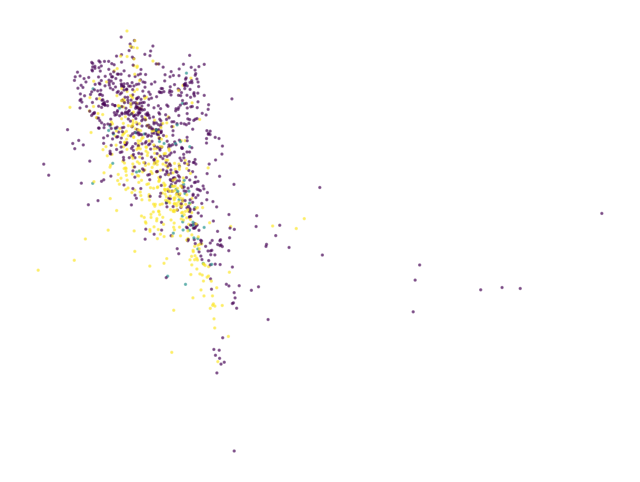

In [37]:
df_p = df
data6 = df_p[df_p['Time_point']==6]
se6 = set(data6['Member'])

df_labels_dic = {}
for idx, row in df_p.iterrows():
    if row['Time_point'] != 6: continue
    if row['Member'] not in df_labels_dic:
        df_labels_dic[row['Member']] = [row['Cell_type_annotation']]
    else:
        df_labels_dic[row['Member']].append(row['Cell_type_annotation'])
print(df_labels_dic)

data2 = df_p[df_p['Time_point']==2]
data4 = df_p[df_p['Time_point']==4]

se2 = set(data2['Member'])
se4 = set(data4['Member'])
se = se6 & se2
data2 = data2[data2['Member'].isin(se)]
x = data2[['SPRING-x', 'SPRING-y']].to_numpy()
x_labels = data2['Member'].to_numpy()
lis = []
soft_lis = []
for i in x_labels:
    tps = df_labels_dic[i]
    m = 0; n = 0
    for tp in tps:
        if tp == 'Neutrophil': n += 1
        else: 
            m += 1
    soft_lis.append(n/(len(tps)))
    if n > m: lis.append(1)
    elif n < m:
        lis.append(-1)
    else: lis.append(0)
print(x.shape)


fig, ax = plt.subplots(figsize=(8, 6))
for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_xticks([]) 
ax.set_yticks([]) 
ax.set_xticklabels([])
ax.set_yticklabels([])  
plt.scatter(x[:, 0], x[:, 1], s=2, c=lis, alpha=0.5)
test = df[df['Member'] == 5]
plt.savefig('mouse_gt.png')

In [38]:
normalized_data = df_p[df_p['Member'].isin(se)]
columns = ['SPRING-x', 'SPRING-y']
for i, col in enumerate(columns):
    mean = normalized_data[col].mean()
    std = normalized_data[col].std()
    normalized_data[col] = (normalized_data[col] - mean) / std
    Mo[col] = (Mo[col] - mean) / std
    Ne[col] = (Ne[col] - mean) / std


C:\Users\A\AppData\Local\Temp\ipykernel_28316\3511236827.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  normalized_data[col] = (normalized_data[col] - mean) / std


In [39]:
data2 = normalized_data[normalized_data['Time_point']==2]
data2 = data2[data2['Member'].isin(se)]
full_x = data2[['SPRING-x', 'SPRING-y']].to_numpy()
full_x_labels = data2['Member'].to_numpy()

data6 = normalized_data[normalized_data['Time_point']==6]
data6 = data6[data6['Member'].isin(se)]
full_y = data6[['SPRING-x', 'SPRING-y']].to_numpy()
full_y_labels = data6['Member'].to_numpy()

data4 = normalized_data[normalized_data['Time_point']==4]
data4 = data4[data4['Member'].isin(se)]
full_z = data4[['SPRING-x', 'SPRING-y']].to_numpy()
full_z_labels = data4['Member'].to_numpy()


full_x.shape, full_y.shape, full_z.shape

((1144, 2), (6477, 2), (3152, 2))

In [40]:
num_to_select = int(len(se) * 0.8)
selected = random.sample(list(se), num_to_select)
se = set(selected)

In [41]:
data2 = normalized_data[normalized_data['Time_point']==2]
data2 = data2[data2['Member'].isin(se)]
x = data2[['SPRING-x', 'SPRING-y']].to_numpy()
x_labels = data2['Member'].to_numpy()

data4 = normalized_data[normalized_data['Time_point']==6]
data4 = data6[data6['Member'].isin(se)]
y = data6[['SPRING-x', 'SPRING-y']].to_numpy()
y_labels = data6['Member'].to_numpy()

data4 = normalized_data[normalized_data['Time_point']==4]
data4 = data4[data4['Member'].isin(se)]
z = data4[['SPRING-x', 'SPRING-y']].to_numpy()
z_labels = data4['Member'].to_numpy()


x.shape, y.shape, z.shape, x_labels.shape, y_labels.shape, z_labels.shape

((899, 2), (6477, 2), (2648, 2), (899,), (6477,), (2648,))

(6477, 2) (6477,)


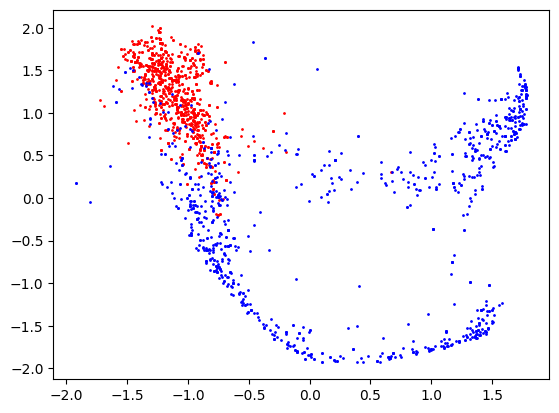

In [42]:
y_labels_dic = {}
print(y.shape, y_labels.shape)
for i in range(len(y_labels)):
    if y_labels[i] not in y_labels_dic:
        y_labels_dic[y_labels[i]] = [i]
    else:
        y_labels_dic[y_labels[i]].append(i)

def sample(x, y, x_labels, y_labels_dic, n):
    x_idx = np.random.randint(0, len(x), n)
    x_sample = x[x_idx]
    x_labels_sample = x_labels[x_idx]
    y_idx = [random.choice(y_labels_dic[i]) for i in x_labels_sample]
    y_sample = np.take(y, y_idx, axis=0)

    return x_sample, y_sample, x_idx, y_idx
x_sample, y_sample, x_idx, y_idx = sample(x, y, x_labels, y_labels_dic, 1000)
plt.scatter(x_sample[:, 0], x_sample[:, 1], s=1, c='red')
plt.scatter(y_sample[:, 0], y_sample[:, 1], s=1, c='blue')

In [43]:
import torch
import torch.nn as nn

class ToyModel(nn.Module):
    def __init__(self, dim, latent_dim, encoder_dims, decoder_dims):
        super(ToyModel, self).__init__()
        self.dim = dim
        self.latent_dim = latent_dim
        self.encoder_dims = encoder_dims
        self.decoder_dims = decoder_dims

        encoder_blocks = [nn.Linear(dim, encoder_dims[0]), nn.ReLU()]
        for i in range(len(encoder_dims)-1):
            encoder_blocks.append(nn.Linear(encoder_dims[i], encoder_dims[i+1]))
            encoder_blocks.append(nn.ReLU())
        encoder_blocks.append(nn.Linear(encoder_dims[-1], latent_dim*2))
        self.encoder_x = nn.Sequential(*encoder_blocks)

        encoder_blocks = [nn.Linear(dim * 2, encoder_dims[0]), nn.ReLU()]
        for i in range(len(encoder_dims)-1):
            encoder_blocks.append(nn.Linear(encoder_dims[i], encoder_dims[i+1]))
            encoder_blocks.append(nn.ReLU())
        encoder_blocks.append(nn.Linear(encoder_dims[-1], latent_dim*2))
        self.encoder_y = nn.Sequential(*encoder_blocks)

        decoder_blocks = [nn.Linear(latent_dim + dim + 2, decoder_dims[0]), nn.ReLU()]
        for i in range(len(decoder_dims)-1):
            decoder_blocks.append(nn.Linear(decoder_dims[i], decoder_dims[i+1]))
            decoder_blocks.append(nn.ReLU())
        decoder_blocks.append(nn.Linear(decoder_dims[-1], dim))
        self.decoder_net = nn.Sequential(*decoder_blocks)

    def encode(self, y, x):
        output = self.encoder_x(x)
        latent_x = output[:, :self.latent_dim]
        logvar_x = output[:, self.latent_dim:]
        output = self.encoder_y(torch.cat([y, x], dim=1))
        latent_y = output[:, :self.latent_dim]
        logvar_y = output[:, self.latent_dim:]
        return latent_x, logvar_x, latent_y, logvar_y

    def forward(self, x, latent, r, t):
        ipt = torch.cat([x, latent, r.view(-1, 1), t.view(-1, 1)], dim=1)
        return self.decoder_net(ipt)
    
    def loss(self, x, r, t, y):
        mu_x, logvar_x, mu_y, logvar_y = self.encode(y, x)
        kl_loss_regular = torch.mean(mu_x**2) + 3 * ( - torch.mean(logvar_x) + torch.mean(torch.exp(logvar_x) ) - 1)
        kl_loss_xy = (torch.mean((mu_y-mu_x)**2) - torch.mean(logvar_y-logvar_x) + torch.mean(torch.exp(logvar_y) / torch.exp(logvar_x) ) - 1)
        
        start = r * y + (1-r) * x
        end = t * y + (1-t) * x
        v = y - x
        latent = mu_y + torch.exp(logvar_y/2) * torch.randn_like(mu_y)
        ipt = torch.cat([start, latent, r.view(-1, 1), t.view(-1, 1)], dim=1)
        tangent = torch.cat([v, torch.zeros_like(latent), torch.ones_like(r), torch.ones_like(t)], dim=1)
        u, jvp = torch.func.jvp(self.decoder_net, (ipt, ), (tangent, ))
        jvp = jvp.detach()
        v_loss = torch.mean((u - v - (t-r) * jvp)**2)
        return {
            'v_loss': v_loss,
            'kl_loss_xy': kl_loss_xy,
            'kl_loss_regular': kl_loss_regular,

        }
    
    def simulation(self, x, use_x=False, y = None, r=0, t=1):
        if use_x:
            output = self.encoder_x(x)
            mu = output[:, :self.latent_dim]
            logvar = output[:, self.latent_dim:]
            latent = mu + torch.exp(logvar/2) * torch.randn_like(mu)
        elif y != None:
            print('hello')
            output = self.encoder_y(torch.cat([y, x], dim=1))
            mu = output[:, :self.latent_dim]
            logvar = output[:, self.latent_dim:]
            latent = mu + torch.exp(logvar/2) * torch.randn_like(mu)
        else:
            latent = torch.randn(x.shape[0], self.latent_dim)
        batch, dim = x.shape
        r = torch.ones((batch, 1)) * r
        t = torch.ones((batch, 1)) * t
        return x + self.decoder_net(torch.cat([x, latent, r, t], dim=1)) * (t-r)


In [44]:
torch.manual_seed(seed)
batch_size = 1024
toy_model = ToyModel(dim, 2, [32, 128, 128, 32], [32, 64, 128, 64, 32])
x = torch.tensor(x, dtype=torch.float32)
optimizer = torch.optim.Adam(toy_model.parameters(), lr=1e-4)
for step in range(20000):
    xx, yy, _, _ = sample(x, y, x_labels, y_labels_dic, batch_size)
    xx = torch.tensor(xx, dtype=torch.float32)
    yy = torch.tensor(yy, dtype=torch.float32)
    tt = torch.rand((batch_size, 1))
    rr = torch.rand((batch_size, 1))
    r = torch.minimum(tt, rr)
    t = torch.maximum(tt, rr)
    optimizer.zero_grad()
    loss = toy_model.loss(xx, r, t, yy)
    if step % 100 == 0:
        print(loss)
    loss = 10 * loss['v_loss'] + 1 * loss['kl_loss_xy'] + 2 * loss['kl_loss_regular']
    loss.backward()
    optimizer.step()


C:\Users\A\AppData\Local\Temp\ipykernel_28316\2071734981.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  xx = torch.tensor(xx, dtype=torch.float32)


{'v_loss': tensor(2.9877, grad_fn=<MeanBackward0>), 'kl_loss_xy': tensor(0.0200, grad_fn=<SubBackward0>), 'kl_loss_regular': tensor(0.0033, grad_fn=<AddBackward0>)}
{'v_loss': tensor(2.4508, grad_fn=<MeanBackward0>), 'kl_loss_xy': tensor(0.0400, grad_fn=<SubBackward0>), 'kl_loss_regular': tensor(0.0029, grad_fn=<AddBackward0>)}
{'v_loss': tensor(0.9994, grad_fn=<MeanBackward0>), 'kl_loss_xy': tensor(0.3690, grad_fn=<SubBackward0>), 'kl_loss_regular': tensor(0.0256, grad_fn=<AddBackward0>)}
{'v_loss': tensor(0.8779, grad_fn=<MeanBackward0>), 'kl_loss_xy': tensor(0.6380, grad_fn=<SubBackward0>), 'kl_loss_regular': tensor(0.0337, grad_fn=<AddBackward0>)}
{'v_loss': tensor(0.7910, grad_fn=<MeanBackward0>), 'kl_loss_xy': tensor(0.9825, grad_fn=<SubBackward0>), 'kl_loss_regular': tensor(0.0394, grad_fn=<AddBackward0>)}
{'v_loss': tensor(0.5256, grad_fn=<MeanBackward0>), 'kl_loss_xy': tensor(1.7923, grad_fn=<SubBackward0>), 'kl_loss_regular': tensor(0.0334, grad_fn=<AddBackward0>)}
{'v_loss':

In [45]:
yyy = toy_model.simulation(torch.tensor(xx, dtype=torch.float32), use_x=True).detach()
ans =wasserstein(torch.tensor(y, dtype=torch.float32), torch.tensor(yyy), power=2)
print(ans)


C:\Users\A\AppData\Local\Temp\ipykernel_28316\3390291306.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  yyy = toy_model.simulation(torch.tensor(xx, dtype=torch.float32), use_x=True).detach()
C:\Users\A\AppData\Local\Temp\ipykernel_28316\3390291306.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  ans =wasserstein(torch.tensor(y, dtype=torch.float32), torch.tensor(yyy), power=2)


0.26894159813350454


In [46]:
from sklearn.neighbors import NearestNeighbors

def smooth_probs_knn(x, probs, k=15):

    is_1d = probs.ndim == 1
    if is_1d:
        probs = probs.reshape(-1, 1)
        
    nbrs = NearestNeighbors(n_neighbors=k, algorithm='auto').fit(x)
    distances, indices = nbrs.kneighbors(x)
    
    smoothed_probs = np.mean(probs[indices], axis=1)
    
    if is_1d:
        smoothed_probs = smoothed_probs.flatten()
        
    return smoothed_probs


C:\Users\A\AppData\Local\Temp\ipykernel_28316\3428498002.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  full_x = torch.tensor(full_x, dtype=torch.float32)


0.11964580979642434
[0.084 0.503 0.54  ... 0.    0.441 0.41 ] [0. 1. 1. ... 0. 1. 0.]


0.8030833897686175

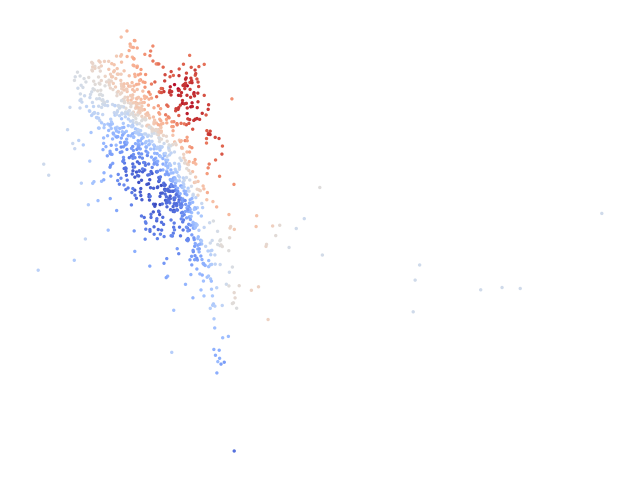

In [50]:
knn = 96

smooth_lis = smooth_probs_knn(full_x, np.array(soft_lis), k=knn)
tri_Mo = scipy.spatial.Delaunay(Mo)
tri_Ne = scipy.spatial.Delaunay(Ne)
type(tri_Mo)
N = 1000
cs = []; ds = []; nes = []; mos = []
full_x = torch.tensor(full_x, dtype=torch.float32)
for k in range(len(full_x)):
    xxx = full_x[k, :].view(2).repeat(N, 1)
    yyy = toy_model.simulation(xxx, use_x=True, y=None).detach().numpy()
    mo_mask = tri_Mo.find_simplex(yyy) >= 0
    ne_mask = tri_Ne.find_simplex(yyy) >= 0
    mo_p = np.sum(mo_mask) / N
    ne_p = np.sum(ne_mask) / N
    cs.append(mo_p - ne_p)
    nes.append(ne_p)
    mos.append(mo_p)
    ds.append(np.sign(mo_p - ne_p))

fig, ax = plt.subplots(figsize=(8, 6))
for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_xticks([])  
ax.set_yticks([]) 
ax.set_xticklabels([])
ax.set_yticklabels([])
plt.scatter(full_x[:,0], full_x[:,1], c=cs, cmap='coolwarm', s=2)


cs_np = np.array(cs); lis_np = np.array(soft_lis); nes_np = np.array(nes); mos_np = np.array(mos)
cs_np = (cs_np + 1) / 2
print(np.mean(np.abs(nes_np-smooth_lis)))
print(nes_np, lis_np)
def spearman_manual(x, y):
    rank_x = np.argsort(np.argsort(x)) + 1
    rank_y = np.argsort(np.argsort(y)) + 1
    return np.corrcoef(rank_x, rank_y)[0, 1]
knn_r = np.corrcoef(nes_np, smooth_lis)[0, 1]
knn_r

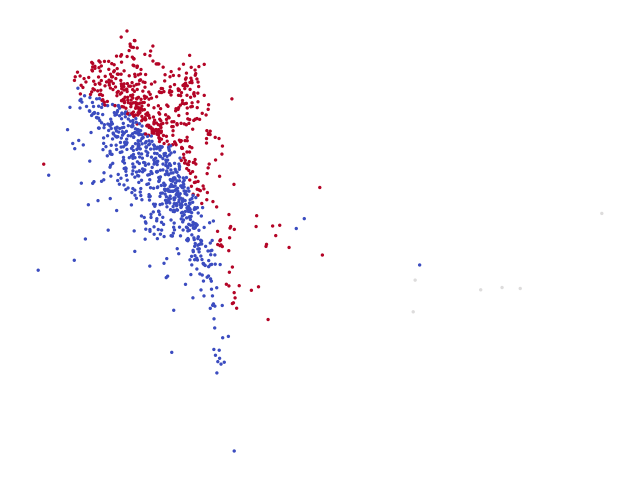

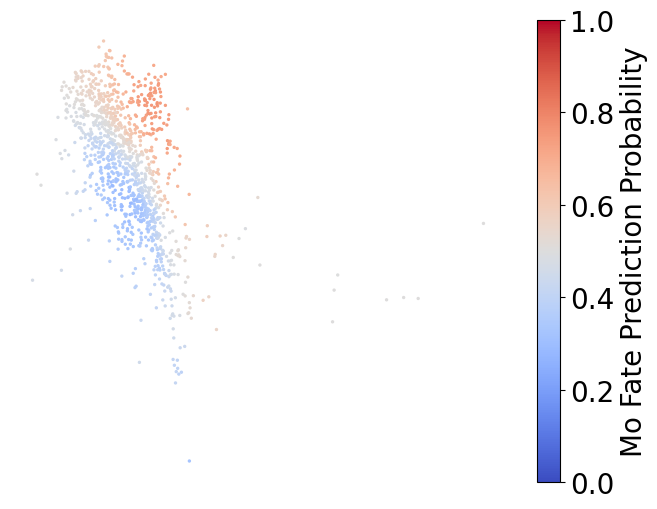

In [ ]:
norm_cs = [(_+1)/2 for _ in cs]
fig, ax = plt.subplots(figsize=(8, 6))
for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_xticks([])  
ax.set_yticks([]) 
ax.set_xticklabels([])
ax.set_yticklabels([])
plt.scatter(full_x[:,0], full_x[:,1], c=ds, cmap='coolwarm', s=2, alpha=1)
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_xticks([])  
ax.set_yticks([]) 
ax.set_xticklabels([])
ax.set_yticklabels([])
scatter = plt.scatter(full_x[:,0], full_x[:,1], c=norm_cs, cmap='coolwarm', s=2, alpha=1, vmin=0, vmax=1)
cbar = plt.colorbar(scatter, ax=ax) 
cbar.set_label('Mo Fate Prediction Probability', fontsize=20)
cbar.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
cbar.set_ticklabels(['0.0', '0.2', '0.4', '0.6', '0.8', '1.0'], fontsize=20)
plt.show()